# Conditional operations: 
1. Fast reset
2. T-gate teleportation
3. Repetition code 

Three feed-forward circuits written with the conditional API (`gates.Switch`,
`gates.IfElse`) of `CQT-qibo`'s `eo-switch-native-execution` branch.

In [ ]:
# Imports
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "CQT-qibo" / "src"))  # checked-out CQT-qibo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qibo
from qibo import Circuit, gates

qibo.set_backend("numpy")

[Qibo 0.3.7|INFO|2026-10-22 00:55:17]: Using numpy backend on /CPU:0


In [11]:
# SSH Helper
import re
import shlex
import subprocess
import time

SSH_HOST = "cqt-paul-server-nqch-deploy"  # existing ~/.ssh/config entry
REMOTE_DIR = "/mnt/home/nqch-deploy/test_qm_run"
REMOTE_PYTHON = "/mnt/scratch/nqch-deploy/eo-switch-native-execution-venv/bin/python"
REMOTE_SCRIPT = f"{REMOTE_DIR}/1_fast_reset.py"
TERMINAL_STATES = {
    "COMPLETED", "FAILED", "CANCELLED", "TIMEOUT", "OUT_OF_MEMORY",
    "NODE_FAIL", "BOOT_FAIL", "DEADLINE", "PREEMPTED", "REVOKED",
}


def _ssh(command: str) -> str:
    completed = subprocess.run(
        ["ssh", "-o", "BatchMode=yes", "-o", "ConnectTimeout=10", SSH_HOST, command],
        stdin=subprocess.DEVNULL,
        capture_output=True,
        text=True,
        timeout=45,
    )
    if completed.returncode:
        raise RuntimeError(f"SSH command failed: {completed.stderr.strip()}")
    return completed.stdout


def _slurm_state(job_id: str) -> str:
    rows = _ssh(f"sacct -X -n -P -j {job_id} --format=JobIDRaw,State")
    for row in rows.splitlines():
        fields = row.split("|", 1)
        if len(fields) == 2 and fields[0].strip() == job_id:
            return fields[1].strip().split()[0].rstrip("+")
    queued = _ssh(f"squeue -h -j {job_id} -o %T").strip()
    return queued.splitlines()[0] if queued else "UNKNOWN"

## Fast reset

A single-round active reset: measure a qubit mid-circuit and apply `X` only if
the outcome is 1, leaving it in $|0\rangle$ ideally. Preparing $|+\rangle$
first exercises both feedback outcomes; the second measurement checks the
reset. Actual feedback speed and reset fidelity must be measured on hardware.

In [12]:
c = Circuit(1)
c.add(gates.H(0))  # prepare |+> so both feedback outcomes occur

before_reset = c.add(gates.M(0, collapse=True, register_name="before_reset"))

c.add(gates.IfElse(
    before_reset.is_one(), 
    then_do=gates.X(0)))
c.add(gates.M(0, register_name="after_reset"))

c.draw()
result = c(nshots=1000)
print("Before reset:", before_reset.frequencies())
print("After reset:", result.frequencies())  # ideally all 0


0: ─H─M─if[─X─][─]─M─
Before reset: Counter({'1': 512, '0': 488})
After reset: Counter({'0': 1000})


<details>
<summary>Hardware version Fast Reset</summary>

```python
# Hardware version Fast reset
"""Run the notebook's one-qubit fast reset on sinq20 through QASM 3 and QM.

Run only inside a user-submitted Slurm job. Logical qubit 0 is pinned to
the physical qubit named by ``PHYSICAL_QUBIT``.
The mid-circuit measurement is saved as ``before_reset``; a conditional X
returns the qubit to |0> when that measurement is one; ``after_reset`` checks
the result. An optional offline QUA preflight uses the QM backend's own
translator to preview whether the measurement-controlled reset survives into
the QUA program before hardware access. The backend compiles again when run()
submits the 1000-shot circuit.
"""


import json
import os
from pathlib import Path

import qiskit.qasm3
from qibo import Circuit, gates
from qibo_qm_provider import FluxTunableTransmonBackend, add_basic_macros
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.controlflow import IfElseOp
from qiskit.transpiler import Layout
from qm import generate_qua_script
from quam_config import Quam


SINQ20_ROOT = Path("/mnt/scratch/qibolab_platforms_nqch/sinq20")
PHYSICAL_QUBIT = "q15"
SHOTS = 1000
ENABLE_QUA_PREFLIGHT = True  # Set to False to skip the optional QUA check.
EXPECTED_REGISTERS = [("before_reset", 1), ("after_reset", 1)]


def build_fast_reset() -> Circuit:
    """Measure |+>, flip a measured one to zero, then measure again."""
    circuit = Circuit(1)
    circuit.add(gates.H(0))
    before_reset = circuit.add(
        gates.M(0, collapse=True, register_name="before_reset")
    )
    circuit.add(gates.IfElse(before_reset.is_one(), then_do=gates.X(0)))
    circuit.add(gates.M(0, register_name="after_reset"))
    return circuit


def qibo_to_openqasm3_to_qiskit(circuit: Circuit) -> QuantumCircuit:
    """Convert the fast-reset circuit through QASM 3 and verify its control flow."""
    qasm = circuit.to_qasm3(qiskit_compatible=True, reuse_registers=False)
    qiskit_circuit = qiskit.qasm3.loads(qasm)
    if len(qiskit_circuit.qubits) != 1:
        raise RuntimeError("Expected exactly one logical qubit")
    if [(reg.name, reg.size) for reg in qiskit_circuit.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QASM import changed the reset measurement registers")
    if sum(isinstance(item.operation, IfElseOp) for item in qiskit_circuit.data) != 1:
        raise RuntimeError("QASM import did not preserve exactly one IfElse")
    if sum(item.operation.name == "measure" for item in qiskit_circuit.data) != 2:
        raise RuntimeError("Expected one feedback and one final measurement")
    return qiskit_circuit


def load_qm_backend():
    """Use the same sinq20 QuAM state, wiring, and macros from working Paul script."""
    machine = Quam.load(filepath_or_dict=SINQ20_ROOT / "state.json")
    with (SINQ20_ROOT / "wiring.json").open() as handle:
        payload = json.load(handle)
    machine.wiring = payload["wiring"]
    machine.network = payload["network"]

    backend = FluxTunableTransmonBackend(machine)
    for pair in machine.qubit_pairs.values():
        pair.macros["cz"] = pair.macros["cz_flattop"]
    add_basic_macros(backend)
    return backend.qiskit_backend


def transpilation(converted_circuit: QuantumCircuit, qm_backend) -> tuple[QuantumCircuit, int]:
    """Place the logical qubit and translate gates for the QM backend target."""
    # First pass: explicitly place logical qubit 0 on PHYSICAL_QUBIT.
    physical_index = qm_backend.qubit_dict[PHYSICAL_QUBIT]
    layout = Layout.from_intlist([physical_index], converted_circuit.qregs[0])
    placed = transpile(converted_circuit, initial_layout=layout, optimization_level=0)
    actual = placed.layout.initial_layout[converted_circuit.qubits[0]]
    if actual != physical_index:
        raise RuntimeError(f"Logical qubit 0 was placed at {actual}, not {physical_index}")

    # Second pass: translate H to QM target gates while retaining IfElse.
    native = transpile(placed, backend=qm_backend, optimization_level=0)
    if sum(isinstance(item.operation, IfElseOp) for item in native.data) != 1:
        raise RuntimeError("QM target translation did not preserve IfElse")
    if [(reg.name, reg.size) for reg in native.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QM target translation changed the measurement registers")
    active_indices = {
        native.find_bit(qubit).index
        for item in native.data for qubit in item.qubits
    }
    if active_indices != {physical_index}:
        raise RuntimeError(
            f"QM target translation moved an operation off {PHYSICAL_QUBIT}"
        )
    return native, physical_index


def run_qua_preflight(qm_backend, native) -> None:
    """Check the generated QUA offline; run() compiles again for submission."""
    compilation = qm_backend.quantum_circuit_to_qua(native)
    qua_script = generate_qua_script(compilation.qua_program)
    if "with if_(" not in qua_script or "with if_(False)" in qua_script:
        raise RuntimeError("Unsafe or missing measurement-dependent QUA branch")
    if set(compilation.outputs.table) != {"before_reset", "after_reset"}:
        raise RuntimeError("Unexpected QUA measurement outputs")
    if qm_backend._qmm is not None or qm_backend._qm is not None:
        raise RuntimeError("The offline preflight unexpectedly opened a QM connection")

    print("QUA branch lines:", flush=True)
    for line in qua_script.splitlines():
        if "with if_(" in line or "with else_(" in line:
            print(f"  {line.strip()}", flush=True)


def report_results(counts, shots: int) -> None:
    """Label the measured reset outcomes and report the final-zero total."""
    # Qiskit displays classical registers in reverse declaration order:
    # after_reset first, before_reset second. The QM provider may omit spaces.
    print("Hardware counts:", flush=True)
    reset_to_zero = 0
    for key, count in sorted(counts.items()):
        bits = key.replace(" ", "")
        if len(bits) != 2 or any(bit not in "01" for bit in bits):
            raise RuntimeError(f"Unexpected after/before reset bit string: {key!r}")
        after_reset, before_reset = bits
        print(
            f"  before_reset={before_reset}  after_reset={after_reset}  shots={count}",
            flush=True,
        )
        if after_reset == "0":
            reset_to_zero += count
    print(f"Final zero outcomes: {reset_to_zero}/{shots}", flush=True)


def main() -> None:
    if not os.environ.get("SLURM_JOB_ID"):
        raise RuntimeError("Run this hardware script only inside a user-submitted Slurm job")

    # 1. Transform Qibo circuit to OpenQASM 3 to Qiskit.
    converted_circuit = qibo_to_openqasm3_to_qiskit(build_fast_reset())

    # 2. Load from Arthur's provider Qiskit-Backend
    qm_backend = load_qm_backend()

    # 3. Transpilation: 
    # 1) Place the logical qubit(s) into physical ones
    # 2) Translate the circuit to QM native gates.
    native, physical_index = transpilation(converted_circuit, qm_backend)
    print(f"Placement: logical 0 -> {PHYSICAL_QUBIT} ({physical_index})", flush=True)
    print(f"Shots: {SHOTS}", flush=True)

    # 4. Optional QUA compilation to check qm_backend.run() will compile correctly.
    if ENABLE_QUA_PREFLIGHT:
        run_qua_preflight(qm_backend, native)

    # 5. Job submission: this submits to QM only when the user submits the enclosing Slurm job.
    job = qm_backend.run(native, shots=SHOTS)
    print(f"QM job ID: {job.job_id()}", flush=True)

    result = job.result()
    if not result.success:
        raise RuntimeError("QM result reported failure")
    
    counts = result.get_counts()
    if sum(counts.values()) != SHOTS:
        raise RuntimeError(f"Expected {SHOTS} results, received {counts}")

    # 6. Print out results
    report_results(counts, SHOTS)

if __name__ == "__main__":
    main()
```
</details>

### Execute on Nqch 

In [13]:
# Fast reset execution functions
def _parse_fast_reset_measurements(raw_stdout: str):
    matches = re.findall(
        r"^\s*before_reset=([01])\s+after_reset=([01])\s+shots=(\d+)\s*$",
        raw_stdout,
        flags=re.MULTILINE,
    )
    if not matches:
        return None
    joint_counts = {}
    for before, after, count in matches:
        label = f"{before}->{after}"  # before_reset -> after_reset
        joint_counts[label] = joint_counts.get(label, 0) + int(count)
    before_counts = {
        bit: sum(n for label, n in joint_counts.items() if label[0] == bit)
        for bit in "01"
    }
    after_counts = {
        bit: sum(n for label, n in joint_counts.items() if label[-1] == bit)
        for bit in "01"
    }
    return {
        "joint_counts": joint_counts,
        "before_reset_counts": before_counts,
        "after_reset_counts": after_counts,
        "final_zero_count": after_counts["0"],
    }


def submit_fast_reset_job(poll_seconds: int = 10, max_wait_seconds: int = 7200):
    """Submit one fast-reset Slurm job, wait, and return its logs and counts."""
    if poll_seconds <= 0 or max_wait_seconds <= 0:
        raise ValueError("Poll and wait durations must be positive")
    _ssh("true")
    print(f"SSH connection to {SSH_HOST}: OK", flush=True)

    wrapped = f"{shlex.quote(REMOTE_PYTHON)} {shlex.quote(REMOTE_SCRIPT)}"
    submit = (
        f"cd {shlex.quote(REMOTE_DIR)} && "
        "sbatch --parsable --partition=sinq20 --job-name=fast_reset "
        f"--chdir={shlex.quote(REMOTE_DIR)} --time=00:30:00 "
        f"--output={shlex.quote(REMOTE_DIR + '/slurm-%j.out')} "
        f"--error={shlex.quote(REMOTE_DIR + '/slurm-%j.err')} "
        f"--wrap={shlex.quote(wrapped)}"
    )
    job_id = _ssh(submit).strip().split(";", 1)[0]
    if not re.fullmatch(r"\d+", job_id):
        raise RuntimeError(f"Could not parse Slurm job ID: {job_id!r}")
    print(f"Submitted Slurm job {job_id}", flush=True)

    started = time.monotonic()
    previous_state = None
    while True:
        status = _slurm_state(job_id)
        if status != previous_state:
            print(f"Job {job_id}: {status}", flush=True)
            previous_state = status
        if status in TERMINAL_STATES:
            break
        if time.monotonic() - started >= max_wait_seconds:
            raise TimeoutError(
                f"Stopped waiting for Slurm job {job_id} while it was {status}; "
                "the job was not cancelled"
            )
        time.sleep(poll_seconds)

    # Output files can appear a moment after Slurm records the final state.
    for attempt in range(5):
        try:
            raw_stdout = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.out')}")
            raw_stderr = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.err')}")
            break
        except RuntimeError:
            if attempt == 4:
                raise
            time.sleep(2)

    return {
        "connection_status": "connected",
        "job_id": job_id,
        "status": status,
        "raw_logs": {"stdout": raw_stdout, "stderr": raw_stderr},
        "measurement_results": _parse_fast_reset_measurements(raw_stdout),
    }


Run the next cell only when you want to submit the fast-reset job. It waits for that job and stores its logs and counts in `fast_reset_job`. Interrupting the notebook wait does not cancel the Slurm job.

In [14]:
fast_reset_job = submit_fast_reset_job()
fast_reset_job["measurement_results"]

SSH connection to cqt-paul-server-nqch-deploy: OK
Submitted Slurm job 65273
Job 65273: RUNNING
Job 65273: COMPLETED


{'joint_counts': {'0->0': 533, '1->0': 372, '0->1': 12, '1->1': 83},
 'before_reset_counts': {'0': 545, '1': 455},
 'after_reset_counts': {'0': 905, '1': 95},
 'final_zero_count': 905}

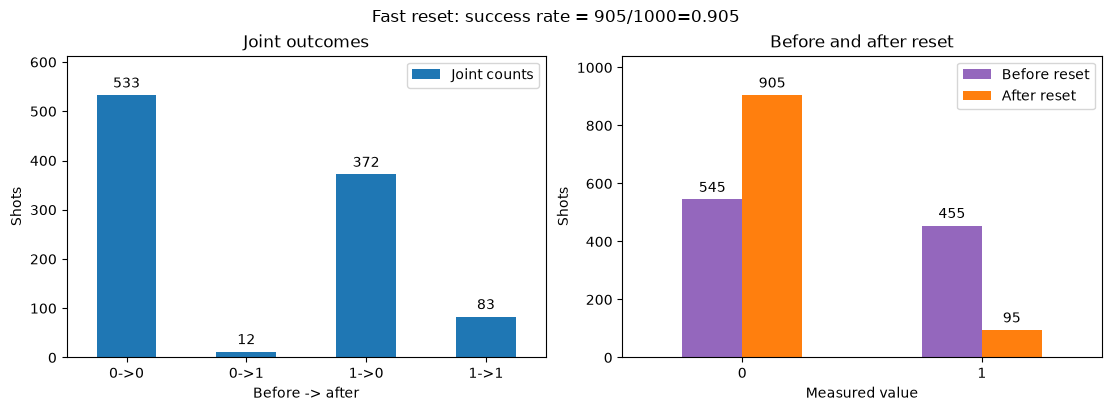

In [17]:
# Plotting
results = fast_reset_job["measurement_results"]
if results is None:
    raise ValueError("No measurement results found; inspect fast_reset_job['raw_logs'].")

transitions = ["0->0", "0->1", "1->0", "1->1"]
joint_counts = pd.DataFrame(
    {"Joint counts": [results["joint_counts"].get(label, 0) for label in transitions]},
    index=transitions,
)
before_after_counts = pd.DataFrame(
    {
        "Before reset": [results["before_reset_counts"].get(bit, 0) for bit in ("0", "1")],
        "After reset": [results["after_reset_counts"].get(bit, 0) for bit in ("0", "1")],
    },
    index=["0", "1"],
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
shots = int(joint_counts["Joint counts"].sum())
succ_rate = results['final_zero_count']/shots
fig.suptitle(f"Fast reset: success rate = {results['final_zero_count']}/{shots}={succ_rate}")
joint_counts.plot.bar(ax=axes[0], color="tab:blue", rot=0, legend=True)
before_after_counts.plot.bar(
    ax=axes[1], color=["tab:purple", "tab:orange"], rot=0, legend=True
)
axes[0].set(title="Joint outcomes", xlabel="Before -> after", ylabel="Shots")
axes[1].set(title="Before and after reset", xlabel="Measured value", ylabel="Shots")
for ax in axes:
    for bars in ax.containers:
        ax.bar_label(bars, padding=3)
    ax.margins(y=0.15)
plt.show()

**How to read the fast-reset plots**

- **Left (blue):** Each bar counts shots with one *before → after* outcome on the same qubit. For example, `1→0` means the first measurement was 1 and the reset left the final measurement at 0. Both `0→0` and `1→0` end at the desired 0.
- **Right (purple and orange):** At each measured value (0 or 1), purple counts outcomes **before** reset and orange counts outcomes **after** reset. A taller orange bar at 0 means more shots ended at 0. The title reports that final-zero count divided by all shots.

## T-gate teleportation

Qubit 0 holds the input $|+\rangle$ and qubit 1 the magic state $T|+\rangle$. After the
CNOT, measuring qubit 1 leaves $T|+\rangle$ on qubit 0 for outcome 0 and $T^\dagger|+\rangle$
for outcome 1, which the conditional $S$ corrects ($S\,T^\dagger = T$). Measuring
$T|+\rangle$ in the X basis gives $P(1) = \sin^2(\pi/8) \approx 0.146$.

In [18]:
c = Circuit(2)

c.add(gates.H(0))

c.add(gates.H(1))
c.add(gates.T(1))
c.add(gates.CNOT(0, 1))
t = c.add(gates.M(1, collapse=True))
c.add(gates.IfElse(t.is_one(), then_do=gates.S(0)))
c.add(gates.H(0))
c.add(gates.M(0))

c.draw()
nshots = 10000
p1 = c(nshots=nshots).frequencies()["1"] / nshots
print(f"P(1) = {p1:.3f}, expected sin^2(pi/8) = {np.sin(np.pi / 8) ** 2:.3f}")

0: ─H───o───if[─S─][─]─H─M─
1: ─H─T─X─M────────────────
P(1) = 0.149, expected sin^2(pi/8) = 0.146


<details>
<summary>Hardware version Teleportation</summary>

```python
"""Run the notebook's T-gate teleportation circuit on sinq20 through QASM 3 and QM.

Run only inside a user-submitted Slurm job. Logical qubits 0 and 1 are pinned
respectively to the physical qubits named in ``PHYSICAL_QUBITS``. The first
measurement controls an S correction on qubit 0; the final X-basis measurement
of qubit 0 should give P(1) near sin^2(pi/8) on ideal hardware. An optional
offline QUA preflight checks that the measurement-dependent branch survives
translation before the backend opens a hardware session. The backend compiles
again when run() submits the 1000-shot circuit.
"""

import json
import math
import os
from pathlib import Path

import qiskit.qasm3
from qibo import Circuit, gates
from qibo_qm_provider import FluxTunableTransmonBackend, add_basic_macros
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.controlflow import IfElseOp
from qiskit.transpiler import Layout
from qm import generate_qua_script
from quam_config import Quam


SINQ20_ROOT = Path("/mnt/scratch/qibolab_platforms_nqch/sinq20")
PHYSICAL_QUBITS = ("q15", "q19")
SHOTS = 1000
ENABLE_QUA_PREFLIGHT = True  # Set to False to skip the optional QUA check.
EXPECTED_REGISTERS = [("feedback", 1), ("result", 1)]


def build_teleportation() -> Circuit:
    """Prepare a magic state, teleport T onto qubit 0, and measure in X."""
    circuit = Circuit(2)
    circuit.add(gates.H(0))
    circuit.add(gates.H(1))
    circuit.add(gates.T(1))
    circuit.add(gates.CNOT(0, 1))
    feedback = circuit.add(gates.M(1, collapse=True, register_name="feedback"))
    circuit.add(gates.IfElse(feedback.is_one(), then_do=gates.S(0)))
    circuit.add(gates.H(0))
    circuit.add(gates.M(0, register_name="result"))
    return circuit


def qibo_to_openqasm3_to_qiskit(circuit: Circuit) -> QuantumCircuit:
    """Convert through OpenQASM 3 and verify the teleportation control flow."""
    qasm = circuit.to_qasm3(qiskit_compatible=True, reuse_registers=False)
    qiskit_circuit = qiskit.qasm3.loads(qasm)
    if len(qiskit_circuit.qubits) != 2:
        raise RuntimeError("Expected exactly two logical qubits")
    if [(reg.name, reg.size) for reg in qiskit_circuit.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QASM import changed the teleportation registers")
    if sum(isinstance(item.operation, IfElseOp) for item in qiskit_circuit.data) != 1:
        raise RuntimeError("QASM import did not preserve exactly one IfElse")
    if sum(item.operation.name == "measure" for item in qiskit_circuit.data) != 2:
        raise RuntimeError("Expected one feedback and one final measurement")
    if sum(item.operation.name == "cx" for item in qiskit_circuit.data) != 1:
        raise RuntimeError("QASM import changed the teleportation CNOT")
    return qiskit_circuit


def load_qm_backend():
    """Use the same sinq20 QuAM state, wiring, and macros as fast reset."""
    machine = Quam.load(filepath_or_dict=SINQ20_ROOT / "state.json")
    with (SINQ20_ROOT / "wiring.json").open() as handle:
        payload = json.load(handle)
    machine.wiring = payload["wiring"]
    machine.network = payload["network"]

    backend = FluxTunableTransmonBackend(machine)
    for pair in machine.qubit_pairs.values():
        pair.macros["cz"] = pair.macros["cz_flattop"]
    add_basic_macros(backend)
    return backend.qiskit_backend


def transpilation(converted_circuit: QuantumCircuit, qm_backend) -> tuple[QuantumCircuit, list[int]]:
    """Place both logical qubits and translate gates for the QM target."""
    physical_indices = [qm_backend.qubit_dict[name] for name in PHYSICAL_QUBITS]
    layout = Layout.from_intlist(physical_indices, converted_circuit.qregs[0])
    placed = transpile(converted_circuit, initial_layout=layout, optimization_level=0)
    for logical_index, physical_index in enumerate(physical_indices):
        actual = placed.layout.initial_layout[converted_circuit.qubits[logical_index]]
        if actual != physical_index:
            raise RuntimeError(
                f"Logical qubit {logical_index} was placed at {actual}, "
                f"not {physical_index}"
            )

    # Translate H, T, S, and CNOT to gates supported by the QM target.
    native = transpile(placed, backend=qm_backend, optimization_level=0)
    if sum(isinstance(item.operation, IfElseOp) for item in native.data) != 1:
        raise RuntimeError("QM target translation did not preserve IfElse")
    if [(reg.name, reg.size) for reg in native.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QM target translation changed the measurement registers")
    active_indices = {
        native.find_bit(qubit).index
        for item in native.data for qubit in item.qubits
    }
    if active_indices != set(physical_indices):
        raise RuntimeError("QM target translation moved an operation off q15/q19")
    if native.count_ops().get("cz", 0) < 1:
        raise RuntimeError("QM target translation did not map CNOT to a CZ")
    return native, physical_indices


def run_qua_preflight(qm_backend, native: QuantumCircuit) -> None:
    """Check the generated QUA offline; run() compiles again for submission."""
    compilation = qm_backend.quantum_circuit_to_qua(native)
    qua_script = generate_qua_script(compilation.qua_program)
    if "with if_(" not in qua_script or "with if_(False)" in qua_script:
        raise RuntimeError("Unsafe or missing measurement-dependent QUA branch")
    if set(compilation.outputs.table) != {"feedback", "result"}:
        raise RuntimeError("Unexpected QUA measurement outputs")
    if qm_backend._qmm is not None or qm_backend._qm is not None:
        raise RuntimeError("The offline preflight unexpectedly opened a QM connection")

    print("QUA branch lines:", flush=True)
    for line in qua_script.splitlines():
        if "with if_(" in line or "with else_(" in line:
            print(f"  {line.strip()}", flush=True)


def report_results(counts, shots: int) -> None:
    """Label feedback/final outcomes and report the final-one frequency."""
    # Qiskit displays registers in reverse declaration order: result, feedback.
    # The QM provider may omit spaces between the two register values.
    print("Hardware counts:", flush=True)
    final_one_count = 0
    for key, count in sorted(counts.items()):
        bits = key.replace(" ", "")
        if len(bits) != 2 or any(bit not in "01" for bit in bits):
            raise RuntimeError(f"Unexpected result/feedback bit string: {key!r}")
        result_bit, feedback_bit = bits
        print(
            f"  feedback={feedback_bit}  result={result_bit}  shots={count}",
            flush=True,
        )
        if result_bit == "1":
            final_one_count += count
    print(f"Final one outcomes: {final_one_count}/{shots}", flush=True)
    print(
        f"P(1) = {final_one_count / shots:.3f}; "
        f"ideal sin^2(pi/8) = {math.sin(math.pi / 8) ** 2:.3f}",
        flush=True,
    )


def main() -> None:
    if not os.environ.get("SLURM_JOB_ID"):
        raise RuntimeError("Run this hardware script only inside a user-submitted Slurm job")

    # 1. Transform the Qibo circuit through OpenQASM 3 to Qiskit.
    converted_circuit = qibo_to_openqasm3_to_qiskit(build_teleportation())

    # 2. Load Arthur's provider Qiskit backend using the sinq20 configuration.
    qm_backend = load_qm_backend()

    # 3. Place both qubits and translate the circuit to QM target gates.
    native, physical_indices = transpilation(converted_circuit, qm_backend)
    print(
        f"Placement: logical 0 -> {PHYSICAL_QUBITS[0]} ({physical_indices[0]}), "
        f"logical 1 -> {PHYSICAL_QUBITS[1]} ({physical_indices[1]})",
        flush=True,
    )
    print(f"Shots: {SHOTS}", flush=True)

    # 4. Optionally check QUA compilation before opening a hardware session.
    if ENABLE_QUA_PREFLIGHT:
        run_qua_preflight(qm_backend, native)

    # 5. The user submits the Slurm job; this call submits to QM once inside it.
    job = qm_backend.run(native, shots=SHOTS)
    print(f"QM job ID: {job.job_id()}", flush=True)
    result = job.result()
    if not result.success:
        raise RuntimeError("QM result reported failure")
    counts = result.get_counts()
    if sum(counts.values()) != SHOTS:
        raise RuntimeError(f"Expected {SHOTS} results, received {counts}")

    # 6. Report measured results.
    report_results(counts, SHOTS)


if __name__ == "__main__":
    main()


```

</details>

### Execute on Nqch 

In [19]:
# Teleportation execution functions
TELEPORTATION_SCRIPT = f"{REMOTE_DIR}/2_teleportation.py"


def _parse_teleportation_measurements(raw_stdout: str):
    matches = re.findall(
        r"^\s*feedback=([01])\s+result=([01])\s+shots=(\d+)\s*$",
        raw_stdout,
        flags=re.MULTILINE,
    )
    if not matches:
        return None

    joint_counts = {}
    for feedback, result, count in matches:
        label = f"{feedback}->{result}"  # feedback measurement -> final measurement
        joint_counts[label] = joint_counts.get(label, 0) + int(count)
    feedback_counts = {
        bit: sum(n for label, n in joint_counts.items() if label[0] == bit)
        for bit in "01"
    }
    result_counts = {
        bit: sum(n for label, n in joint_counts.items() if label[-1] == bit)
        for bit in "01"
    }
    shots = sum(joint_counts.values())
    if shots == 0:
        raise RuntimeError("Teleportation log contains no measurement shots")
    final_one_count = result_counts["1"]

    summary = re.search(
        r"^Final one outcomes:\s*(\d+)/(\d+)\s*$",
        raw_stdout,
        flags=re.MULTILINE,
    )
    if summary and (int(summary.group(1)), int(summary.group(2))) != (final_one_count, shots):
        raise RuntimeError("Teleportation summary disagrees with the hardware counts")

    return {
        "joint_counts": joint_counts,
        "feedback_counts": feedback_counts,
        "result_counts": result_counts,
        "final_one_count": final_one_count,
        "shots": shots,
        "p1": final_one_count / shots,
    }


def submit_teleportation_job(poll_seconds: int = 10, max_wait_seconds: int = 7200):
    """Submit one teleportation Slurm job, wait, and return its logs and counts."""
    if poll_seconds <= 0 or max_wait_seconds <= 0:
        raise ValueError("Poll and wait durations must be positive")
    _ssh("true")
    print(f"SSH connection to {SSH_HOST}: OK", flush=True)

    wrapped = f"{shlex.quote(REMOTE_PYTHON)} {shlex.quote(TELEPORTATION_SCRIPT)}"
    submit = (
        f"cd {shlex.quote(REMOTE_DIR)} && "
        "sbatch --parsable --partition=sinq20 --job-name=teleportation "
        f"--chdir={shlex.quote(REMOTE_DIR)} --time=00:30:00 "
        f"--output={shlex.quote(REMOTE_DIR + '/slurm-%j.out')} "
        f"--error={shlex.quote(REMOTE_DIR + '/slurm-%j.err')} "
        f"--wrap={shlex.quote(wrapped)}"
    )
    job_id = _ssh(submit).strip().split(";", 1)[0]
    if not re.fullmatch(r"\d+", job_id):
        raise RuntimeError(f"Could not parse Slurm job ID: {job_id!r}")
    print(f"Submitted Slurm job {job_id}", flush=True)

    started = time.monotonic()
    previous_state = None
    while True:
        status = _slurm_state(job_id)
        if status != previous_state:
            print(f"Job {job_id}: {status}", flush=True)
            previous_state = status
        if status in TERMINAL_STATES:
            break
        if time.monotonic() - started >= max_wait_seconds:
            raise TimeoutError(
                f"Stopped waiting for Slurm job {job_id} while it was {status}; "
                "the job was not cancelled"
            )
        time.sleep(poll_seconds)

    # Output files can appear a moment after Slurm records the final state.
    for attempt in range(5):
        try:
            raw_stdout = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.out')}")
            raw_stderr = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.err')}")
            break
        except RuntimeError:
            if attempt == 4:
                raise
            time.sleep(2)

    return {
        "connection_status": "connected",
        "job_id": job_id,
        "status": status,
        "raw_logs": {"stdout": raw_stdout, "stderr": raw_stderr},
        "measurement_results": _parse_teleportation_measurements(raw_stdout),
    }


Run the next cell only when you want to submit the teleportation job. It waits for that job and stores its logs and counts in `teleportation_job`. Interrupting the notebook wait does not cancel the Slurm job.

In [20]:
teleportation_job = submit_teleportation_job()
print("Teleportation measurement results:", teleportation_job["measurement_results"])

SSH connection to cqt-paul-server-nqch-deploy: OK
Submitted Slurm job 65280
Job 65280: PENDING
Job 65280: COMPLETED
Teleportation measurement results: {'joint_counts': {'0->0': 451, '1->0': 388, '0->1': 79, '1->1': 82}, 'feedback_counts': {'0': 530, '1': 470}, 'result_counts': {'0': 839, '1': 161}, 'final_one_count': 161, 'shots': 1000, 'p1': 0.161}


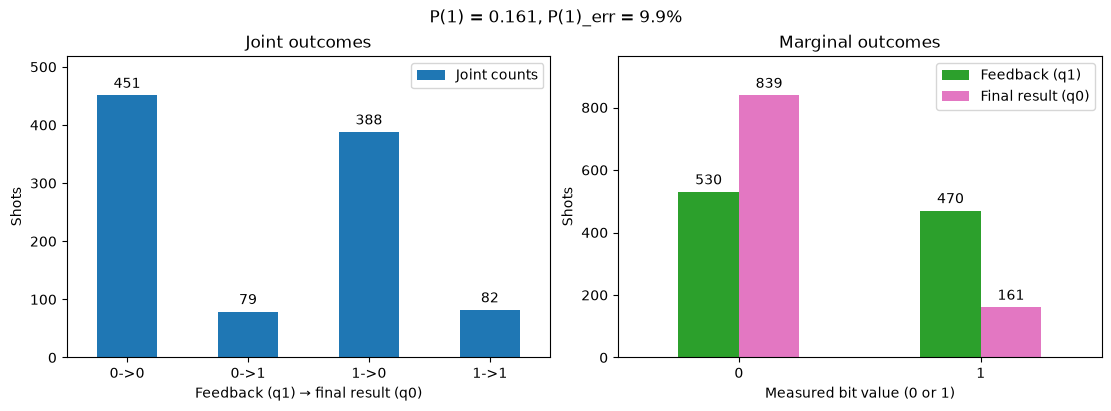

In [21]:
# Teleportation plots
results = teleportation_job["measurement_results"]
if results is None:
    raise ValueError("No measurement results found; inspect teleportation_job['raw_logs'].")

transitions = ["0->0", "0->1", "1->0", "1->1"]
teleportation_joint_counts = pd.DataFrame(
    {"Joint counts": [results["joint_counts"].get(label, 0) for label in transitions]},
    index=transitions,
)
teleportation_marginal_counts = pd.DataFrame(
    {
        "Feedback (q1)": [results["feedback_counts"].get(bit, 0) for bit in ("0", "1")],
        "Final result (q0)": [results["result_counts"].get(bit, 0) for bit in ("0", "1")],
    },
    index=["0", "1"],
)

p1 = results["p1"]
theoretical_p1 = np.sin(np.pi / 8) ** 2  # Approximately 0.146
relative_error_percent = abs(p1 - theoretical_p1) / theoretical_p1 * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
fig.suptitle(f"P(1) = {p1:.3f}, P(1)_err = {relative_error_percent:.1f}%")
teleportation_joint_counts.plot.bar(ax=axes[0], color="tab:blue", rot=0, legend=True)
teleportation_marginal_counts.plot.bar(
    ax=axes[1], color=["tab:green", "tab:pink"], rot=0, legend=True
)
axes[0].set(
    title="Joint outcomes",
    xlabel="Feedback (q1) → final result (q0)",
    ylabel="Shots",
)
axes[1].set(
    title="Marginal outcomes",
    xlabel="Measured bit value (0 or 1)",
    ylabel="Shots",
)
for ax in axes:
    for bars in ax.containers:
        ax.bar_label(bars, padding=3)
    ax.margins(y=0.15)
plt.show()

**How to read the teleportation plots**

- **Left (blue):** Each bar pairs two measurements from one shot: *feedback on q1 → final result on q0*. For example, `1→0` means q1 measured 1 (triggering the `S` correction), then q0's final measurement was 0. The arrow does **not** show one qubit changing from 1 to 0.
- **Right (green and pink):** The x-axis is the measured bit value, 0 or 1. Green counts how often q1 gave that **feedback** value; pink counts how often q0 gave that **final result** value. The title's `P(1)` is the fraction of final q0 results equal to 1; `P(1)_err` is its absolute percentage error relative to the ideal value, about 0.146.

## Repetition code

Data qubits 0, 2, 4 and ancillas 1, 3. Each ancilla measures the $ZZ$ parity of its two
neighbours, and a `Switch` on the syndrome flips the data qubit it points to. Bit 0 of
the syndrome (ancilla 1) is the most significant.

In [2]:
data = [0, 2, 4]
anc = [1, 3]
c = Circuit(5)

# Add error manually
c.add(gates.X(data[1]))

c.add(gates.H(anc[0]))
c.add(gates.H(anc[1]))
c.add(gates.CZ(anc[0], data[0]))
c.add(gates.CZ(anc[1], data[1]))
c.add(gates.CZ(anc[0], data[1]))
c.add(gates.CZ(anc[1], data[2]))
c.add(gates.H(anc[0]))
c.add(gates.H(anc[1]))

syndrome = c.add(gates.M(*anc, collapse=True))

c.add(
    gates.Switch(syndrome)
    .case("10", gates.X(data[0]))
    .case("11", gates.X(data[1]))
    .case("01", gates.X(data[2]))
    .default([])  # "00": no error
)

c.add(gates.M(*data))

c.draw()
print(c(nshots=100).frequencies())  # all 000

0: ───Z───────────switch[─X─][───][───][─]─M─
1: ─H─o───o───H─M─|─────────|────|────|──|─|─
2: ─X───Z─Z─────|─switch[───][─X─][───][─]─M─
3: ─H───o───o─H─M─|─────────|────|────|──|─|─
4: ─────────Z─────switch[───][───][─X─][─]─M─


Counter({'000': 100})


<details>
<summary>Hardware version Repetition Code</summary>

```python
"""Run the notebook's five-qubit repetition code on sinq20 through QASM 3 and QM.

Fill in ``PHYSICAL_QUBITS`` below before a user submits this as a Slurm job.
The list follows logical order: data 0, ancilla 1, data 2, ancilla 3, data 4.
Those physical qubits must support CZ on every neighboring logical pair.
The q15/q19 entries are a provisional first connected pair and may be moved
if the available five-qubit path requires a different order.

Qibo exports the syndrome Switch as nested OpenQASM 3 if/else comparisons on
the two-bit syndrome register. The optional QUA preflight checks for the known
constant-False compilation failure before the backend opens a hardware session.
A downstream compiler fix is still required for correct hardware feedback.
"""

import json
import os
import re
from pathlib import Path

import qiskit.qasm3
from qibo import Circuit, gates
from qibo_qm_provider import FluxTunableTransmonBackend, add_basic_macros
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.controlflow import IfElseOp
from qiskit.transpiler import Layout
from qm import generate_qua_script
from quam_config import Quam


SINQ20_ROOT = Path("/mnt/scratch/qibolab_platforms_nqch/sinq20")
SHOTS = 1000
ENABLE_QUA_PREFLIGHT = True  # Keep enabled when testing the compiler fix.

# Edit this list after finding a connected five-qubit path. List positions are
# logical qubits 0, 1, 2, 3, 4 (data, ancilla, data, ancilla, data).
PHYSICAL_QUBITS = [
    "q15",  # logical 0: data
    "q19",  # logical 1: ancilla, connected to logical 0
    None,   # logical 2: data
    None,   # logical 3: ancilla
    None,   # logical 4: data
]

# Each pair must have a calibrated CZ. Together these form the 0-1-2-3-4 path.
REQUIRED_CZ_EDGES = ((1, 0), (3, 2), (1, 2), (3, 4))
EXPECTED_REGISTERS = [("syndrome", 2), ("result", 3)]
EXPECTED_SYNDROME_CASES = (1, 3, 2)  # QASM integer values for 10, 11, 01.


def validate_physical_qubits() -> tuple[str, ...]:
    """Refuse to submit while the five-qubit placement is incomplete."""
    if len(PHYSICAL_QUBITS) != 5:
        raise RuntimeError("PHYSICAL_QUBITS must list exactly five qubit labels")
    if any(not isinstance(name, str) or not name for name in PHYSICAL_QUBITS):
        raise RuntimeError(
            "Fill every PHYSICAL_QUBITS entry with a physical qubit label; "
            "the logical order is data, ancilla, data, ancilla, data"
        )
    if len(set(PHYSICAL_QUBITS)) != 5:
        raise RuntimeError("PHYSICAL_QUBITS must contain five distinct qubits")
    return tuple(PHYSICAL_QUBITS)


def build_repetition() -> Circuit:
    """Inject X on data qubit 2, measure parity, correct, then measure data."""
    data = (0, 2, 4)
    ancilla = (1, 3)
    circuit = Circuit(5)

    circuit.add(gates.X(data[1]))
    circuit.add(gates.H(ancilla[0]))
    circuit.add(gates.H(ancilla[1]))
    circuit.add(gates.CZ(ancilla[0], data[0]))
    circuit.add(gates.CZ(ancilla[1], data[1]))
    circuit.add(gates.CZ(ancilla[0], data[1]))
    circuit.add(gates.CZ(ancilla[1], data[2]))
    circuit.add(gates.H(ancilla[0]))
    circuit.add(gates.H(ancilla[1]))

    syndrome = circuit.add(
        gates.M(*ancilla, collapse=True, register_name="syndrome")
    )
    circuit.add(
        gates.Switch(syndrome)
        .case("10", gates.X(data[0]))
        .case("11", gates.X(data[1]))
        .case("01", gates.X(data[2]))
        .default([])
    )
    circuit.add(gates.M(*data, register_name="result"))
    return circuit


def syndrome_conditions(circuit: QuantumCircuit) -> list[tuple]:
    """Find all nested if/else comparisons produced from the Qibo Switch."""
    conditions = []
    for item in circuit.data:
        operation = item.operation
        if isinstance(operation, IfElseOp):
            conditions.append(operation.condition)
            for block in operation.blocks:
                conditions.extend(syndrome_conditions(block))
    return conditions


def verify_syndrome_switch(circuit: QuantumCircuit, stage: str) -> None:
    """Check that all three syndrome cases retain their Qiskit control flow."""
    conditions = syndrome_conditions(circuit)
    if len(conditions) != 3:
        raise RuntimeError(f"{stage} did not preserve all three syndrome cases")
    if tuple(value for _, value in conditions) != EXPECTED_SYNDROME_CASES:
        raise RuntimeError(f"{stage} changed the syndrome case values")
    if any(register.name != "syndrome" or register.size != 2 for register, _ in conditions):
        raise RuntimeError(f"{stage} changed the syndrome condition register")


def qibo_to_openqasm3_to_qiskit(circuit: Circuit) -> QuantumCircuit:
    """Convert through OpenQASM 3 and check the five-qubit circuit."""
    qasm = circuit.to_qasm3(qiskit_compatible=True, reuse_registers=False)
    qiskit_circuit = qiskit.qasm3.loads(qasm)
    if len(qiskit_circuit.qubits) != 5:
        raise RuntimeError("Expected exactly five logical qubits")
    if [(reg.name, reg.size) for reg in qiskit_circuit.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QASM import changed the measurement registers")
    if sum(item.operation.name == "measure" for item in qiskit_circuit.data) != 5:
        raise RuntimeError("Expected two syndrome and three final measurements")
    if sum(item.operation.name == "cz" for item in qiskit_circuit.data) != 4:
        raise RuntimeError("Expected all four parity-check CZ gates")
    verify_syndrome_switch(qiskit_circuit, "QASM import")
    return qiskit_circuit


def load_qm_backend():
    """Use the same sinq20 QuAM state, wiring, and macros as the earlier scripts."""
    machine = Quam.load(filepath_or_dict=SINQ20_ROOT / "state.json")
    with (SINQ20_ROOT / "wiring.json").open() as handle:
        payload = json.load(handle)
    machine.wiring = payload["wiring"]
    machine.network = payload["network"]

    backend = FluxTunableTransmonBackend(machine)
    for pair in machine.qubit_pairs.values():
        pair.macros["cz"] = pair.macros["cz_flattop"]
    add_basic_macros(backend)
    return backend.qiskit_backend


def physical_indices_and_connectivity(qm_backend, names: tuple[str, ...]) -> list[int]:
    """Resolve labels and confirm the CZ links needed by the repetition code."""
    unknown = [name for name in names if name not in qm_backend.qubit_dict]
    if unknown:
        raise RuntimeError(f"Physical qubit labels are absent from sinq20: {unknown}")
    indices = [qm_backend.qubit_dict[name] for name in names]
    target = qm_backend.target
    for left, right in REQUIRED_CZ_EDGES:
        pair = (indices[left], indices[right])
        if not (
            target.instruction_supported(operation_name="cz", qargs=pair)
            or target.instruction_supported(operation_name="cz", qargs=pair[::-1])
        ):
            raise RuntimeError(
                f"No CZ connection for logical {left}-{right} "
                f"({names[left]}-{names[right]}); choose a connected five-qubit path"
            )
    return indices


def transpilation(
    converted_circuit: QuantumCircuit, qm_backend, physical_indices: list[int]
) -> QuantumCircuit:
    """Place the five qubits and translate gates to the QM target."""
    layout = Layout.from_intlist(physical_indices, converted_circuit.qregs[0])
    placed = transpile(converted_circuit, initial_layout=layout, optimization_level=0)
    for logical_index, physical_index in enumerate(physical_indices):
        actual = placed.layout.initial_layout[converted_circuit.qubits[logical_index]]
        if actual != physical_index:
            raise RuntimeError(
                f"Logical qubit {logical_index} was placed at {actual}, "
                f"not {physical_index}"
            )

    native = transpile(placed, backend=qm_backend, optimization_level=0)
    verify_syndrome_switch(native, "QM target translation")
    if [(reg.name, reg.size) for reg in native.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QM target translation changed the measurement registers")
    active_indices = {
        native.find_bit(qubit).index
        for item in native.data for qubit in item.qubits
    }
    if active_indices != set(physical_indices):
        raise RuntimeError("QM target translation moved an operation off the selected qubits")
    if native.count_ops().get("cz", 0) != 4:
        raise RuntimeError("QM target translation did not preserve all four CZ gates")
    return native


def run_qua_preflight(qm_backend, native: QuantumCircuit) -> None:
    """Reject the known constant-False switch failure before QM submission."""
    compilation = qm_backend.quantum_circuit_to_qua(native)
    qua_script = generate_qua_script(compilation.qua_program)
    if re.search(r"with\s+(?:if_|elif_|case_)\(\s*False\s*\)", qua_script):
        raise RuntimeError("QUA compiler reduced a syndrome branch to constant False")
    if not any(token in qua_script for token in ("with if_(", "with switch_(")):
        raise RuntimeError("QUA compiler emitted no syndrome control flow")
    if set(compilation.outputs.table) != {"syndrome", "result"}:
        raise RuntimeError("Unexpected QUA measurement outputs")
    if qm_backend._qmm is not None or qm_backend._qm is not None:
        raise RuntimeError("The offline preflight unexpectedly opened a QM connection")

    print("QUA control-flow lines:", flush=True)
    for line in qua_script.splitlines():
        if any(token in line for token in ("with if_(", "with elif_(", "with else_(", "with switch_(", "with case_(")):
            print(f"  {line.strip()}", flush=True)


def report_results(counts, shots: int) -> None:
    """Print syndrome in q1/q3 order and final data in q0/q2/q4 order."""
    # Qiskit counts display registers in reverse declaration order, and each
    # register's bits in reverse index order: result[2:0], syndrome[1:0].
    print("Hardware counts:", flush=True)
    final_zero_count = 0
    for key, count in sorted(counts.items()):
        bits = key.replace(" ", "")
        if len(bits) != 5 or any(bit not in "01" for bit in bits):
            raise RuntimeError(f"Unexpected result/syndrome bit string: {key!r}")
        data_result = bits[:3][::-1]  # q0, q2, q4
        syndrome = bits[3:][::-1]    # q1, q3; matches Switch case strings
        print(
            f"  syndrome={syndrome}  data_result={data_result}  shots={count}",
            flush=True,
        )
        if data_result == "000":
            final_zero_count += count
    print(f"Final 000 outcomes: {final_zero_count}/{shots}", flush=True)


def main() -> None:
    if not os.environ.get("SLURM_JOB_ID"):
        raise RuntimeError("Run this hardware script only inside a user-submitted Slurm job")
    physical_names = validate_physical_qubits()

    # 1. Transform the Qibo circuit through OpenQASM 3 to Qiskit.
    converted_circuit = qibo_to_openqasm3_to_qiskit(build_repetition())

    # 2. Load the sinq20 backend and check every selected CZ connection.
    qm_backend = load_qm_backend()
    physical_indices = physical_indices_and_connectivity(qm_backend, physical_names)

    # 3. Place all five qubits and translate to QM target gates.
    native = transpilation(converted_circuit, qm_backend, physical_indices)
    print("Placement (logical -> physical):", flush=True)
    for logical_index, (name, physical_index) in enumerate(zip(physical_names, physical_indices)):
        print(f"  {logical_index} -> {name} ({physical_index})", flush=True)
    print(f"Shots: {SHOTS}", flush=True)

    # 4. Optionally check QUA compilation before opening a hardware session.
    if ENABLE_QUA_PREFLIGHT:
        run_qua_preflight(qm_backend, native)

    # 5. The user submits the Slurm job; this call submits to QM once inside it.
    job = qm_backend.run(native, shots=SHOTS)
    print(f"QM job ID: {job.job_id()}", flush=True)
    result = job.result()
    if not result.success:
        raise RuntimeError("QM result reported failure")
    counts = result.get_counts()
    if sum(counts.values()) != SHOTS:
        raise RuntimeError(f"Expected {SHOTS} results, received {counts}")

    # 6. Report syndrome and corrected final data outcomes.
    report_results(counts, SHOTS)


if __name__ == "__main__":
    main()


```

</details>

### Execute on Nqch

In [22]:
# Repetition-code execution functions
REPETITION_SCRIPT = f"{REMOTE_DIR}/3_repetition.py"


def _parse_repetition_measurements(raw_stdout: str):
    matches = re.findall(
        r"^\s*syndrome=([01]{2})\s+data_result=([01]{3})\s+shots=(\d+)\s*$",
        raw_stdout,
        flags=re.MULTILINE,
    )
    if not matches:
        return None

    joint_counts = {}
    syndrome_counts = {f"{value:02b}": 0 for value in range(4)}
    data_result_counts = {f"{value:03b}": 0 for value in range(8)}
    for syndrome, data_result, count_text in matches:
        count = int(count_text)
        label = f"{syndrome}->{data_result}"  # ancillas q1/q3 -> data q0/q2/q4
        joint_counts[label] = joint_counts.get(label, 0) + count
        syndrome_counts[syndrome] += count
        data_result_counts[data_result] += count

    shots = sum(joint_counts.values())
    if shots == 0:
        raise RuntimeError("Repetition-code log contains no measurement shots")
    final_zero_count = data_result_counts["000"]

    summary = re.search(
        r"^Final 000 outcomes:\s*(\d+)/(\d+)\s*$",
        raw_stdout,
        flags=re.MULTILINE,
    )
    if summary and (int(summary.group(1)), int(summary.group(2))) != (final_zero_count, shots):
        raise RuntimeError("Repetition-code summary disagrees with the hardware counts")

    return {
        "joint_counts": joint_counts,
        "syndrome_counts": syndrome_counts,
        "data_result_counts": data_result_counts,
        "final_zero_count": final_zero_count,
        "shots": shots,
        "final_zero_fraction": final_zero_count / shots,
    }


def submit_repetition_job(poll_seconds: int = 10, max_wait_seconds: int = 7200):
    """Submit one repetition-code Slurm job, wait, and return its logs and counts."""
    if poll_seconds <= 0 or max_wait_seconds <= 0:
        raise ValueError("Poll and wait durations must be positive")
    _ssh("true")
    print(f"SSH connection to {SSH_HOST}: OK", flush=True)

    wrapped = f"{shlex.quote(REMOTE_PYTHON)} {shlex.quote(REPETITION_SCRIPT)}"
    submit = (
        f"cd {shlex.quote(REMOTE_DIR)} && "
        "sbatch --parsable --partition=sinq20 --job-name=repetition "
        f"--chdir={shlex.quote(REMOTE_DIR)} --time=00:30:00 "
        f"--output={shlex.quote(REMOTE_DIR + '/slurm-%j.out')} "
        f"--error={shlex.quote(REMOTE_DIR + '/slurm-%j.err')} "
        f"--wrap={shlex.quote(wrapped)}"
    )
    job_id = _ssh(submit).strip().split(";", 1)[0]
    if not re.fullmatch(r"\d+", job_id):
        raise RuntimeError(f"Could not parse Slurm job ID: {job_id!r}")
    print(f"Submitted Slurm job {job_id}", flush=True)

    started = time.monotonic()
    previous_state = None
    while True:
        status = _slurm_state(job_id)
        if status != previous_state:
            print(f"Job {job_id}: {status}", flush=True)
            previous_state = status
        if status in TERMINAL_STATES:
            break
        if time.monotonic() - started >= max_wait_seconds:
            raise TimeoutError(
                f"Stopped waiting for Slurm job {job_id} while it was {status}; "
                "the job was not cancelled"
            )
        time.sleep(poll_seconds)

    # Output files can appear a moment after Slurm records the final state.
    for attempt in range(5):
        try:
            raw_stdout = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.out')}")
            raw_stderr = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.err')}")
            break
        except RuntimeError:
            if attempt == 4:
                raise
            time.sleep(2)

    return {
        "connection_status": "connected",
        "job_id": job_id,
        "status": status,
        "raw_logs": {"stdout": raw_stdout, "stderr": raw_stderr},
        "measurement_results": _parse_repetition_measurements(raw_stdout),
    }


Run the next cell only after filling `PHYSICAL_QUBITS` with a connected five-qubit path in the server’s `3_repetition.py` and verifying the downstream switch compiler fix. It submits a Slurm job, waits, and stores logs and counts in `repetition_job`. Interrupting the notebook wait does not cancel the job.

In [ ]:
repetition_job = submit_repetition_job()
print("Repetition-code measurement results:", repetition_job["measurement_results"])

In [ ]:
# Repetition-code syndrome and final-data distributions
from matplotlib.patches import Patch

results = repetition_job["measurement_results"]
if results is None:
    raise ValueError("No measurement results found; inspect repetition_job['raw_logs'].")

syndrome_labels = ["00", "01", "10", "11"]
data_labels = [f"{value:03b}" for value in range(8)]
syndrome_counts = pd.Series(
    {label: results["syndrome_counts"].get(label, 0) for label in syndrome_labels}
)
data_result_counts = pd.Series(
    {label: results["data_result_counts"].get(label, 0) for label in data_labels}
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
fig.suptitle(
    f"Repetition code: final 000 = {results['final_zero_count']}/{results['shots']} "
    f"({results['final_zero_fraction']:.1%})"
)
syndrome_colors = ["tab:green" if label == "11" else "tab:blue" for label in syndrome_labels]
data_colors = ["tab:green" if label == "000" else "tab:orange" for label in data_labels]
syndrome_counts.plot.bar(ax=axes[0], color=syndrome_colors, rot=0)
data_result_counts.plot.bar(ax=axes[1], color=data_colors, rot=0)
axes[0].set(title="Syndrome counts", xlabel="Syndrome (ancillas q1, q3)", ylabel="Shots")
axes[1].set(title="Final data counts", xlabel="Final data (q0, q2, q4)", ylabel="Shots")
axes[0].legend(handles=[
    Patch(color="tab:blue", label="Other syndrome"),
    Patch(color="tab:green", label="Expected: 11"),
])
axes[1].legend(handles=[
    Patch(color="tab:orange", label="Other result"),
    Patch(color="tab:green", label="Expected: 000"),
])
for ax in axes:
    for bars in ax.containers:
        ax.bar_label(bars, padding=3)
    ax.margins(y=0.15)
plt.show()

**How to read the repetition-code bar plots**

- **Left — syndrome:** Each bar counts shots with one two-bit measurement from ancillas **q1, q3**. The circuit deliberately flips the middle data qubit, so `11` (green) is the expected syndrome: both parity checks detect it. The other bars show how often a different syndrome was measured.
- **Right — final data:** Each three-bit label is the final measurement of data qubits **q0, q2, q4**, in that order. After the conditional correction, `000` (green) is the expected result. The title shows how many shots ended in `000` out of all shots; it describes this specific injected-error experiment.

In [ ]:
# Repetition-code joint outcomes: syndrome versus final data
from matplotlib.patches import Rectangle

results = repetition_job["measurement_results"]
if results is None:
    raise ValueError("No measurement results found; inspect repetition_job['raw_logs'].")

syndrome_labels = ["00", "01", "10", "11"]
data_labels = [f"{value:03b}" for value in range(8)]
joint_matrix = pd.DataFrame(0, index=syndrome_labels, columns=data_labels)
for outcome, count in results["joint_counts"].items():
    syndrome, data_result = outcome.split("->")
    joint_matrix.loc[syndrome, data_result] += count

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
image = ax.imshow(joint_matrix.to_numpy(), cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(data_labels)), data_labels)
ax.set_yticks(range(len(syndrome_labels)), syndrome_labels)
ax.set(
    title="Joint outcomes (green outline: expected 11→000)",
    xlabel="Final data (q0, q2, q4)",
    ylabel="Syndrome (ancillas q1, q3)",
)
fig.colorbar(image, ax=ax, label="Shots")
ax.add_patch(Rectangle((-0.5, 2.5), 1, 1, fill=False, edgecolor="limegreen", linewidth=2))
peak_count = joint_matrix.to_numpy().max()
for row, syndrome in enumerate(syndrome_labels):
    for column, data_result in enumerate(data_labels):
        count = joint_matrix.loc[syndrome, data_result]
        if count:
            ax.text(
                column, row, str(count), ha="center", va="center",
                color="white" if count > peak_count / 2 else "black",
            )
plt.show()

**How to read the repetition-code heatmap**

Each square counts shots with **both** the row's syndrome (ancillas q1, q3) and the column's final data result (q0, q2, q4). Darker blue and a larger printed number mean more shots. The green outline marks `11` with `000`: the expected syndrome and corrected result for the deliberately injected error. For example, row `10`, column `100` means q1/q3 measured `10` and q0/q2/q4 later measured `100` in the same shot. Other squares show departures from the ideal pairing; the plot alone does not tell us their cause.